# Feature correlation

Pearson correlation of the 83 model inputs. NSW1, April-June 2025, 30 minute horizon.

In [1]:
import sys
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parents[1]))   # notebook lives in model_research/connor
warnings.filterwarnings("ignore")

from data_cleaning.data import getTrainTestData
from preprocessing import prepare_model_data

REGION = "NSW1"
START = datetime(2025, 4, 1)
END = datetime(2025, 7, 1)      # 3 month sample so this runs quickly
HORIZON = 30

In [2]:
train, test = getTrainTestData(regions=[REGION], start=START, end=END, include_p5min=True)
data = prepare_model_data(region=REGION, horizon=HORIZON, target="change", train_data=train, test_data=test)

features = data.features
X = data.train_df[features]
print(f"{len(features)} features, {len(X):,} training rows")

INFO: Compiling data for table DISPATCHPRICE
INFO: Returning DISPATCHPRICE.
INFO: Compiling data for table DISPATCHREGIONSUM
INFO: Returning DISPATCHREGIONSUM.
INFO: Compiling data for table DISPATCHINTERCONNECTORRES
INFO: Returning DISPATCHINTERCONNECTORRES.
INFO: Compiling REGIONSOLUTION data from the processed cache
INFO: Compiling REGIONSOLUTION data from the processed cache
INFO: Compiling REGIONSOLUTION data from the processed cache
83 features, 20,960 training rows


## Correlation matrix

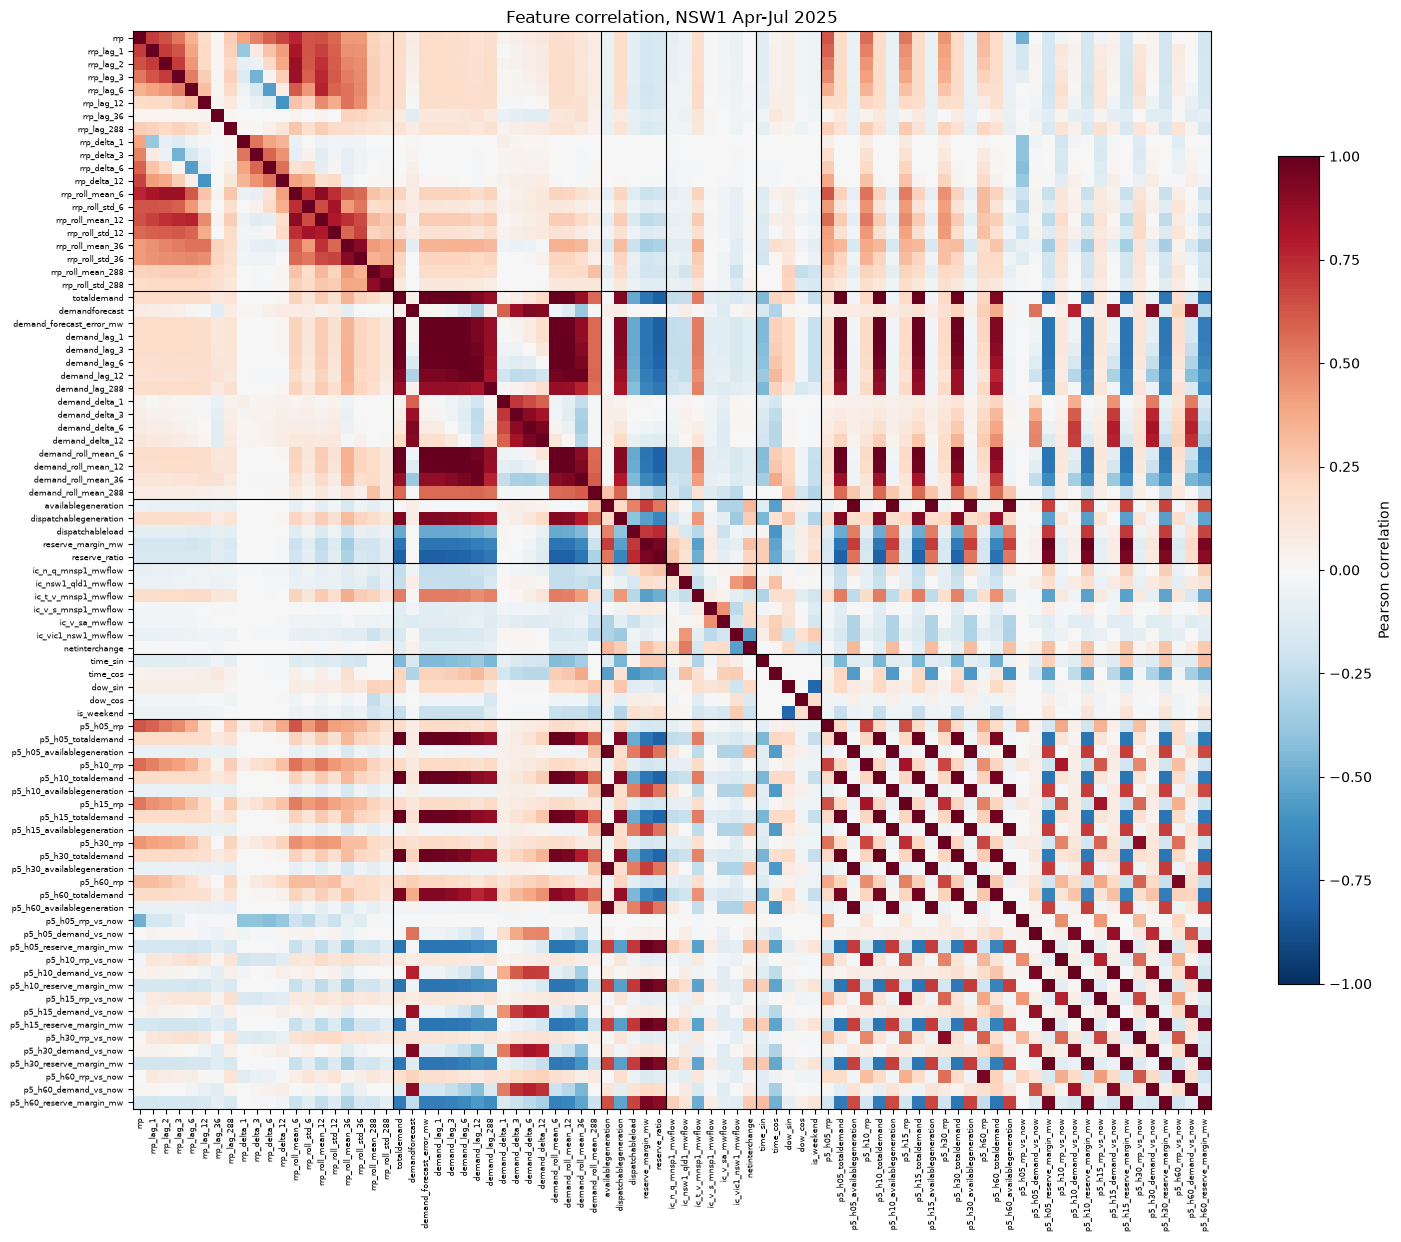

In [3]:
groups = {
    "price now & past": [c for c in features if c.startswith("rrp")],
    "demand now & past": [c for c in features if c.startswith("demand") or c == "totaldemand"],
    "supply": ["availablegeneration", "dispatchablegeneration", "dispatchableload",
               "reserve_margin_mw", "reserve_ratio"],
    "interconnectors": [c for c in features if c.startswith("ic_")] + ["netinterchange"],
    "clock": ["time_sin", "time_cos", "dow_sin", "dow_cos", "is_weekend"],
    "AEMO P5MIN": [c for c in features if c.startswith("p5_")],
}

ordered = [c for cols in groups.values() for c in cols]
corr = X[ordered].corr(method="pearson")
abs_corr = corr.abs()      # direction doesn't matter for redundancy, only strength

fig, ax = plt.subplots(figsize=(15, 13))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(ordered)), ordered, rotation=90, fontsize=6)
ax.set_yticks(range(len(ordered)), ordered, fontsize=6)

edge = 0
for cols in list(groups.values())[:-1]:
    edge += len(cols)
    ax.axhline(edge - 0.5, color="black", lw=0.8)
    ax.axvline(edge - 0.5, color="black", lw=0.8)

fig.colorbar(image, ax=ax, shrink=0.7, label="Pearson correlation")
ax.set_title(f"Feature correlation, {REGION} {START:%b}-{END:%b %Y}")
plt.tight_layout()
plt.show()

## Near-duplicate pairs

In [4]:
pairs = (abs_corr
         .stack()
         .reset_index()
         .set_axis(["feature A", "feature B", "correlation"], axis=1))
pairs = pairs[pairs["feature A"] < pairs["feature B"]]        # keep each pair once
pairs = pairs.sort_values("correlation", ascending=False)

print(f"pairs at 0.95 or above: {(pairs['correlation'] >= 0.95).sum()}")
print(f"pairs at 0.99 or above: {(pairs['correlation'] >= 0.99).sum()}")
pairs.head(15).round(3)

pairs at 0.95 or above: 93
pairs at 0.99 or above: 48


,feature A,feature B,correlation
4791,p5_h10_totaldemand,p5_h15_totaldemand,1.000
4539,p5_h05_totaldemand,p5_h10_totaldemand,1.000
1846,demand_forecast_error_mw,totaldemand,1.000
2024,demand_lag_3,demand_roll_mean_6,0.999
5883,p5_h05_reserve_margin_mw,p5_h10_reserve_margin_mw,0.999
6135,p5_h10_reserve_margin_mw,p5_h15_reserve_margin_mw,0.999
2108,demand_lag_6,demand_roll_mean_12,0.999
1849,demand_forecast_error_mw,demand_lag_1,0.999
4623,p5_h05_availablegeneration,p5_h10_availablegeneration,0.999
4875,p5_h10_availablegeneration,p5_h15_availablegeneration,0.999


## Dropping correlated features
Testing error change for XGboost model dropping highly correlated features (for different correlation thresholds)

In [5]:
from xgboost import XGBRegressor

from model_research.common.experiment_pipeline import (
    ExperimentConfig,
    chronological_validation_split,
    complete_case_rows,
)

# from model_research/chapo/XGBoost_Model.py
PARAMS = {
    "max_depth": 4, "learning_rate": 0.03, "subsample": 0.85, "colsample_bytree": 0.85,
    "min_child_weight": 8, "reg_alpha": 0.1, "reg_lambda": 8.0, "objective": "reg:absoluteerror",
    "eval_metric": "rmse", "tree_method": "hist", "max_bin": 256, "n_jobs": -1, "random_state": 42,
}

config = ExperimentConfig(region=REGION, horizon_minutes=HORIZON, target_type="change", validation_fraction=0.2)
fit_df, validation_df = chronological_validation_split(data.train_df, config)
fit_df = complete_case_rows(fit_df, features)
validation_df = complete_case_rows(validation_df, features)


def prune(features, threshold):
    kept = []
    for feature in features:
        if all(abs_corr.loc[feature, k] < threshold for k in kept):
            kept.append(feature)
    return kept


def validation_mae(chosen, label):
    model = XGBRegressor(n_estimators=2000, early_stopping_rounds=100, **PARAMS)
    model.fit(fit_df[chosen], fit_df["target"],
              eval_set=[(validation_df[chosen], validation_df["target"])], verbose=False)

    # the model predicts the price change, so add it to the current price
    predicted = validation_df["rrp"] + model.predict(validation_df[chosen])
    mae = (validation_df["target_rrp"] - predicted).abs().mean()
    return {"feature set": label, "features": len(chosen), "validation MAE $": round(mae, 2)}


history_features = [c for c in features if "_lag_" in c or "_roll_" in c or "_delta_" in c]
raw_state_features = [c for c in features if c not in history_features]

results = [validation_mae(features, "all features")]
for threshold in (0.99, 0.95, 0.90, 0.80):
    results.append(validation_mae(prune(features, threshold), f"pruned at {threshold}"))
results.append(validation_mae(raw_state_features, "no lags/rolling/deltas"))

no_change = (validation_df["target_rrp"] - validation_df["rrp"]).abs().mean()
print(f"validation rows: {len(validation_df):,}   'no change' baseline MAE: ${no_change:.2f}")
pd.DataFrame(results)

validation rows: 4,192   'no change' baseline MAE: $75.01


,feature set,features,validation MAE $
0,all features,83,69.55
1,pruned at 0.99,68,69.57
2,pruned at 0.95,61,69.59
3,pruned at 0.9,51,69.91
4,pruned at 0.8,42,70.11
5,no lags/rolling/deltas,51,69.85
